# Visualização dos resultados

## Importações

In [1]:
import json
import numpy as np
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from torch.utils.data import DataLoader
from skimage.metrics import structural_similarity

from nucleo import (
    transformacao, dividir_arquivos, DatasetReconstrucao, AutoencoderCNN,
    carregar_imagem, euler_exato,
    SEED, SEED_VALIDACAO, TAMANHO
)

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Configurações

In [2]:
PASTA_TILE = Path("datasets/MVTecAD/tile")
PASTA_MODELOS = Path("modelos")
PASTA_SAIDA = Path("resultados")
PASTA_SAIDA.mkdir(exist_ok=True)

N_EXEMPLOS = 6        
LIMIAR = 0.5          
CONECTIVIDADE = 1     # 1 = vizinhanca 4 | 2 = vizinhanca 8

# Modelos
CAMINHOS = {
    "Com Euler": PASTA_MODELOS / "autoencoder_euler.pth",
    "Sem Euler": PASTA_MODELOS / "autoencoder_baseline.pth",
}


## Carregar modelos

In [3]:
modelos = {}

for nome, caminho in CAMINHOS.items():

    if caminho.exists():
        modelo = AutoencoderCNN().to(dispositivo)
        modelo.load_state_dict(torch.load(caminho, map_location=dispositivo))
        modelo.eval()

        modelos[nome] = modelo

print("Modelos carregados:", list(modelos))

Modelos carregados: ['Com Euler', 'Sem Euler']


## Validação

In [4]:
_, arquivos_validacao = dividir_arquivos(PASTA_TILE / "train" / "good", seed=SEED)

dataset_validacao = DatasetReconstrucao(arquivos_validacao, transformacao, danos_fixos=True, semente=SEED_VALIDACAO)

entradas = torch.stack([dataset_validacao[i][0] for i in range(len(dataset_validacao))])
alvos = torch.stack([dataset_validacao[i][1] for i in range(len(dataset_validacao))])

def reconstruir(modelo, imagens):

    saidas = []

    with torch.no_grad():
        for inicio in range(0, len(imagens), 16):
            lote = imagens[inicio:inicio + 16].to(dispositivo)
            saidas.append(modelo(lote).cpu())

    return torch.cat(saidas)

reconstrucoes = {nome: reconstruir(m, entradas) for nome, m in modelos.items()}

print("Imagens de validacao:", len(alvos))

Imagens de validacao: 35


## Curvas de treinamento

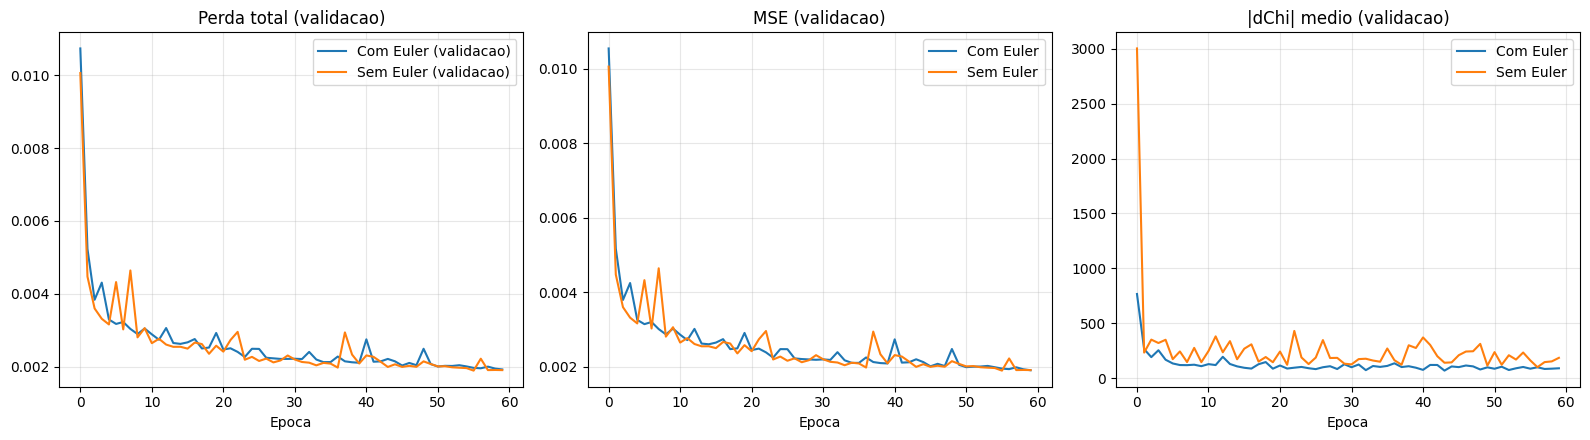

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5))

for nome, caminho in CAMINHOS.items():

    arquivo = caminho.with_name(caminho.stem + "_historico.json")

    if not arquivo.exists():
        continue

    with open(arquivo) as f:
        h = json.load(f)

    eixos[0].plot(h["validacao"], label=f"{nome} (validacao)")
    eixos[1].plot(h["mse_validacao"], label=nome)
    eixos[2].plot(h["euler_validacao"], label=nome)

eixos[0].set_title("Perda total (validacao)")
eixos[1].set_title("MSE (validacao)")
eixos[2].set_title("|dChi| medio (validacao)")

for eixo in eixos:
    eixo.set_xlabel("Epoca")
    eixo.grid(alpha=0.3)
    eixo.legend()

plt.tight_layout()
plt.savefig(PASTA_SAIDA / "curvas_treinamento.png", dpi=150, bbox_inches="tight")
plt.show()


## Comparação de imagens (danificada/ reconstruída/ original/ erro)

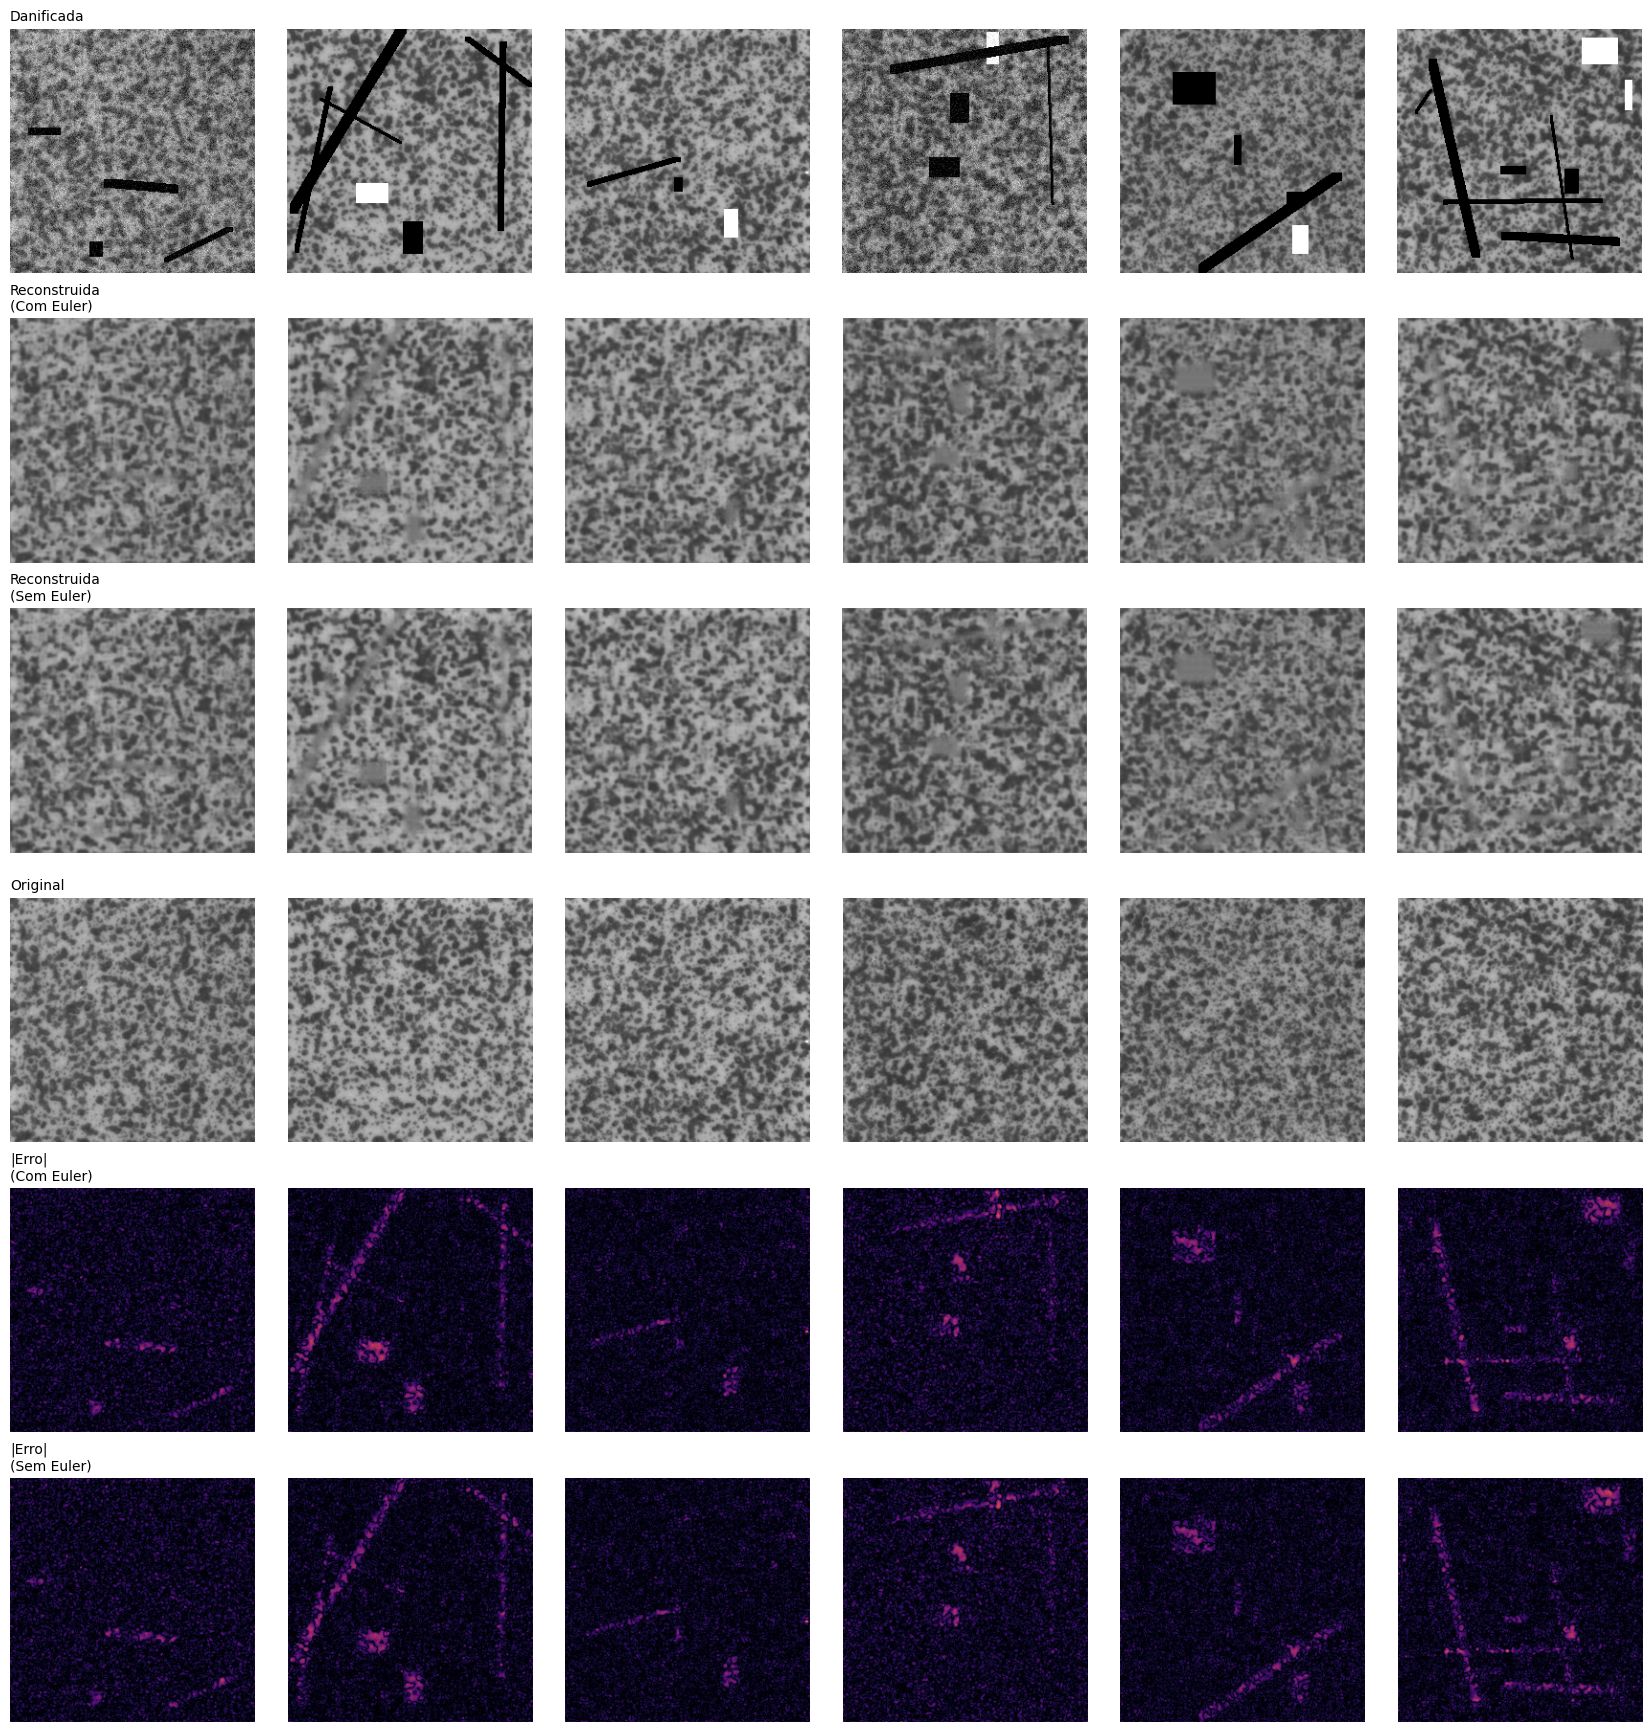

In [6]:
linhas = [("Danificada", entradas, "gray")]

for nome, rec in reconstrucoes.items():
    linhas.append((f"Reconstruida\n({nome})", rec, "gray"))

linhas.append(("Original", alvos, "gray"))

for nome, rec in reconstrucoes.items():
    linhas.append((f"|Erro|\n({nome})", (rec - alvos).abs(), "inferno"))

fig, eixos = plt.subplots(len(linhas), N_EXEMPLOS, figsize=(2.8 * N_EXEMPLOS, 2.9 * len(linhas)), squeeze=False)

for l, (titulo, imagens, mapa) in enumerate(linhas):

    for i in range(N_EXEMPLOS):

        eixos[l, i].imshow(imagens[i, 0], cmap=mapa, vmin=0, vmax=1 if mapa == "gray" else 0.5)
        eixos[l, i].axis("off")

        if i == 0:
            eixos[l, i].set_title(titulo, fontsize=10, loc="left")

plt.tight_layout()
plt.savefig(PASTA_SAIDA / "reconstrucoes.png", dpi=150, bbox_inches="tight")
plt.show()


## Métricas de reconstrução (todo o conjunto de validação)

In [7]:
def metricas(a, b):

    a = a[0].numpy()
    b = b[0].numpy()

    mse = float(np.mean((a - b) ** 2))
    psnr = 10 * np.log10(1.0 / max(mse, 1e-12))
    ssim = structural_similarity(a, b, data_range=1.0)

    return mse, psnr, ssim

tabela = {"Danificada": np.array([metricas(entradas[i], alvos[i]) for i in range(len(alvos))])}

for nome, rec in reconstrucoes.items():
    tabela[nome] = np.array([metricas(rec[i], alvos[i]) for i in range(len(alvos))])

print(f"{'':14s}{'MSE':>20s}{'PSNR (dB)':>20s}{'SSIM':>18s}")

for nome, valores in tabela.items():

    m = valores.mean(axis=0)
    s = valores.std(axis=0)

    print(
        f"{nome:14s}"
        f"{m[0]:12.5f} +/- {s[0]:.5f}"
        f"{m[1]:11.2f} +/- {s[1]:.2f}"
        f"{m[2]:10.4f} +/- {s[2]:.4f}"
    )

print()

for nome in reconstrucoes:

    melhorou = np.mean(tabela[nome][:, 0] < tabela["Danificada"][:, 0]) * 100
    print(f"{nome}: MSE menor que o da imagem danificada em {melhorou:.1f}% das imagens")

if "Sem Euler" in reconstrucoes:

    com = tabela["Com Euler"][:, 0]
    sem = tabela["Sem Euler"][:, 0]

    print(f"\nCom Euler tem MSE menor que Sem Euler em {np.mean(com < sem) * 100:.1f}% das imagens")


                               MSE           PSNR (dB)              SSIM
Danificada         0.01729 +/- 0.00732      18.17 +/- 2.46    0.7204 +/- 0.1478
Com Euler          0.00190 +/- 0.00041      27.31 +/- 1.00    0.8489 +/- 0.0274
Sem Euler          0.00189 +/- 0.00041      27.34 +/- 1.01    0.8497 +/- 0.0273

Com Euler: MSE menor que o da imagem danificada em 100.0% das imagens
Sem Euler: MSE menor que o da imagem danificada em 100.0% das imagens

Com Euler tem MSE menor que Sem Euler em 40.0% das imagens


## Característica de Euler exata, após binarização

Erro medio |chi - chi_original| (menor = topologia mais fiel):

  Danificada  :   862.34
  Com Euler   :    85.60
  Sem Euler   :    88.29


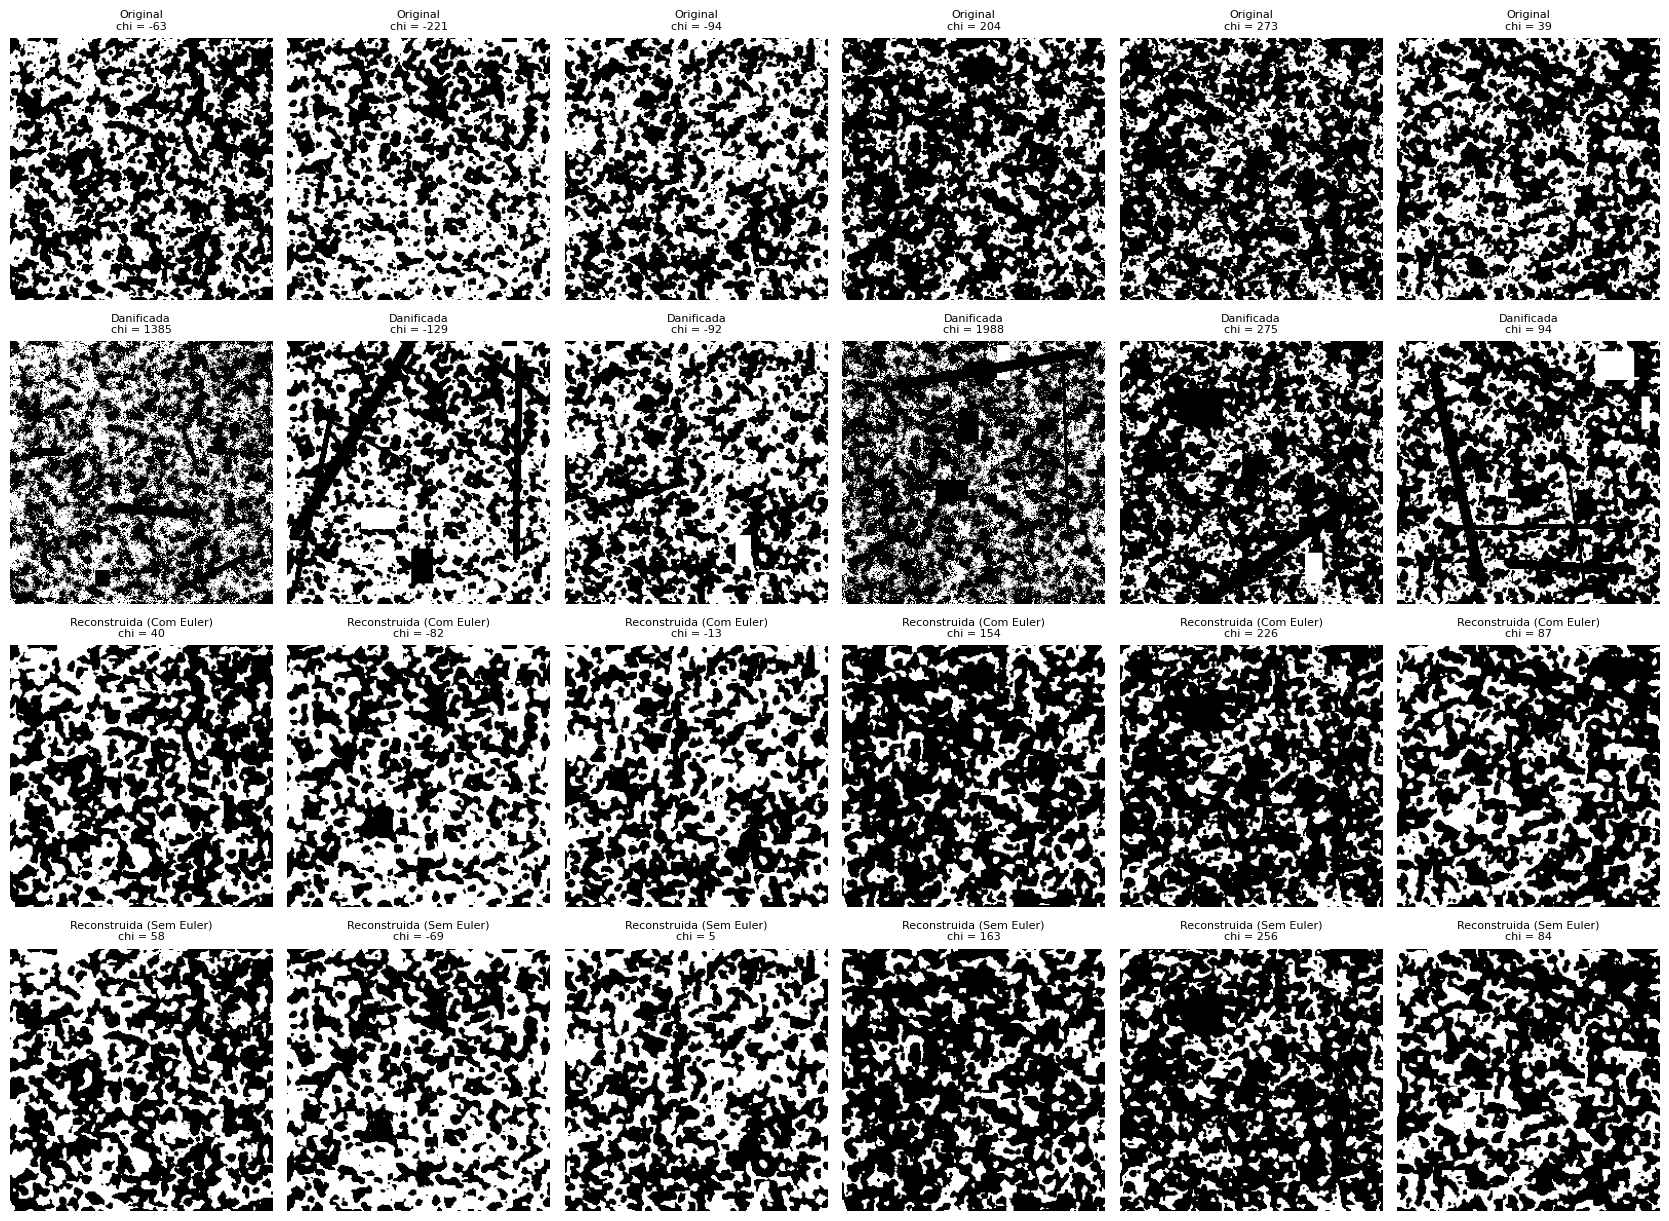

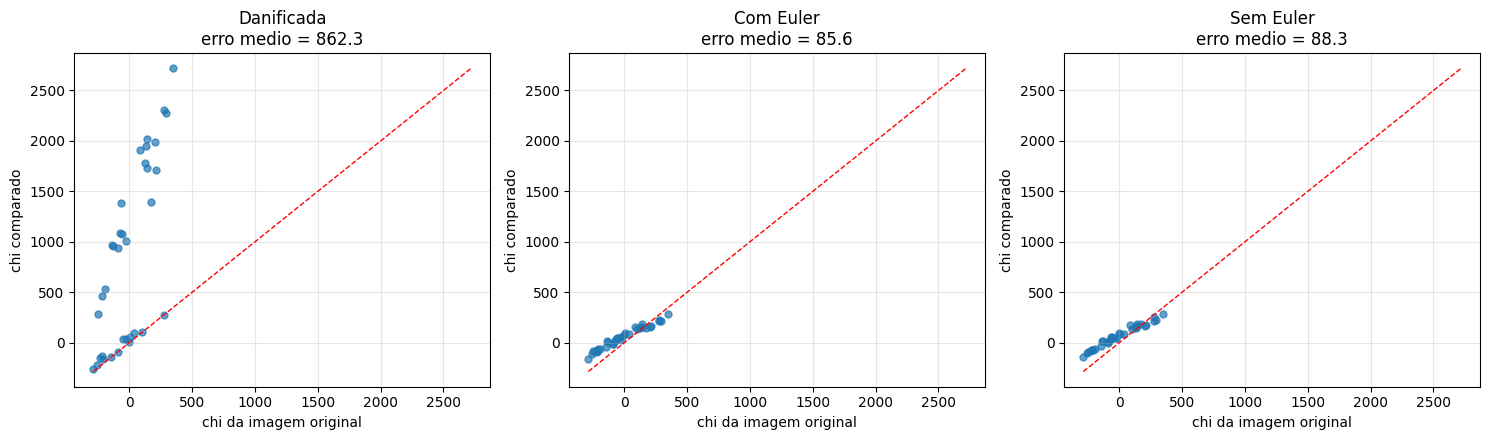

In [8]:
def chi(imagem):
    return euler_exato(imagem[0].numpy(), LIMIAR, CONECTIVIDADE)

chi_alvo = np.array([chi(a) for a in alvos])

chis = {"Danificada": np.array([chi(e) for e in entradas])}

for nome, rec in reconstrucoes.items():
    chis[nome] = np.array([chi(r) for r in rec])

print("Erro medio |chi - chi_original| (menor = topologia mais fiel):\n")

for nome, valores in chis.items():
    print(f"  {nome:12s}: {np.mean(np.abs(valores - chi_alvo)):8.2f}")

# ------------------------------------------------------------
# FIGURA 3: imagens binarizadas com chi

linhas = [("Original", alvos, chi_alvo), ("Danificada", entradas, chis["Danificada"])]

for nome, rec in reconstrucoes.items():
    linhas.append((f"Reconstruida ({nome})", rec, chis[nome]))

fig, eixos = plt.subplots(len(linhas), N_EXEMPLOS, figsize=(2.8 * N_EXEMPLOS, 3.1 * len(linhas)), squeeze=False)

for l, (titulo, imagens, valores) in enumerate(linhas):

    for i in range(N_EXEMPLOS):

        eixos[l, i].imshow(imagens[i, 0] > LIMIAR, cmap="gray")
        eixos[l, i].set_title(f"{titulo}\nchi = {valores[i]}", fontsize=8)
        eixos[l, i].axis("off")

plt.tight_layout()
plt.savefig(PASTA_SAIDA / "euler_binarizadas.png", dpi=150, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# FIGURA 4: chi comparado vs chi original

comparados = [(n, v) for n, v in chis.items()]

fig, eixos = plt.subplots(1, len(comparados), figsize=(5 * len(comparados), 4.5), squeeze=False)

limite = [min(chi_alvo.min(), *[v.min() for _, v in comparados]), max(chi_alvo.max(), *[v.max() for _, v in comparados]),]

for eixo, (nome, valores) in zip(eixos[0], comparados):

    eixo.scatter(chi_alvo, valores, s=25, alpha=0.7)
    eixo.plot(limite, limite, "r--", linewidth=1)

    eixo.set_xlabel("chi da imagem original")
    eixo.set_ylabel("chi comparado")
    eixo.set_title(f"{nome}\nerro medio = {np.mean(np.abs(valores - chi_alvo)):.1f}")
    eixo.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(PASTA_SAIDA / "euler_dispersao.png", dpi=150, bbox_inches="tight")
plt.show()


## Defeitos reais do MVTec AD

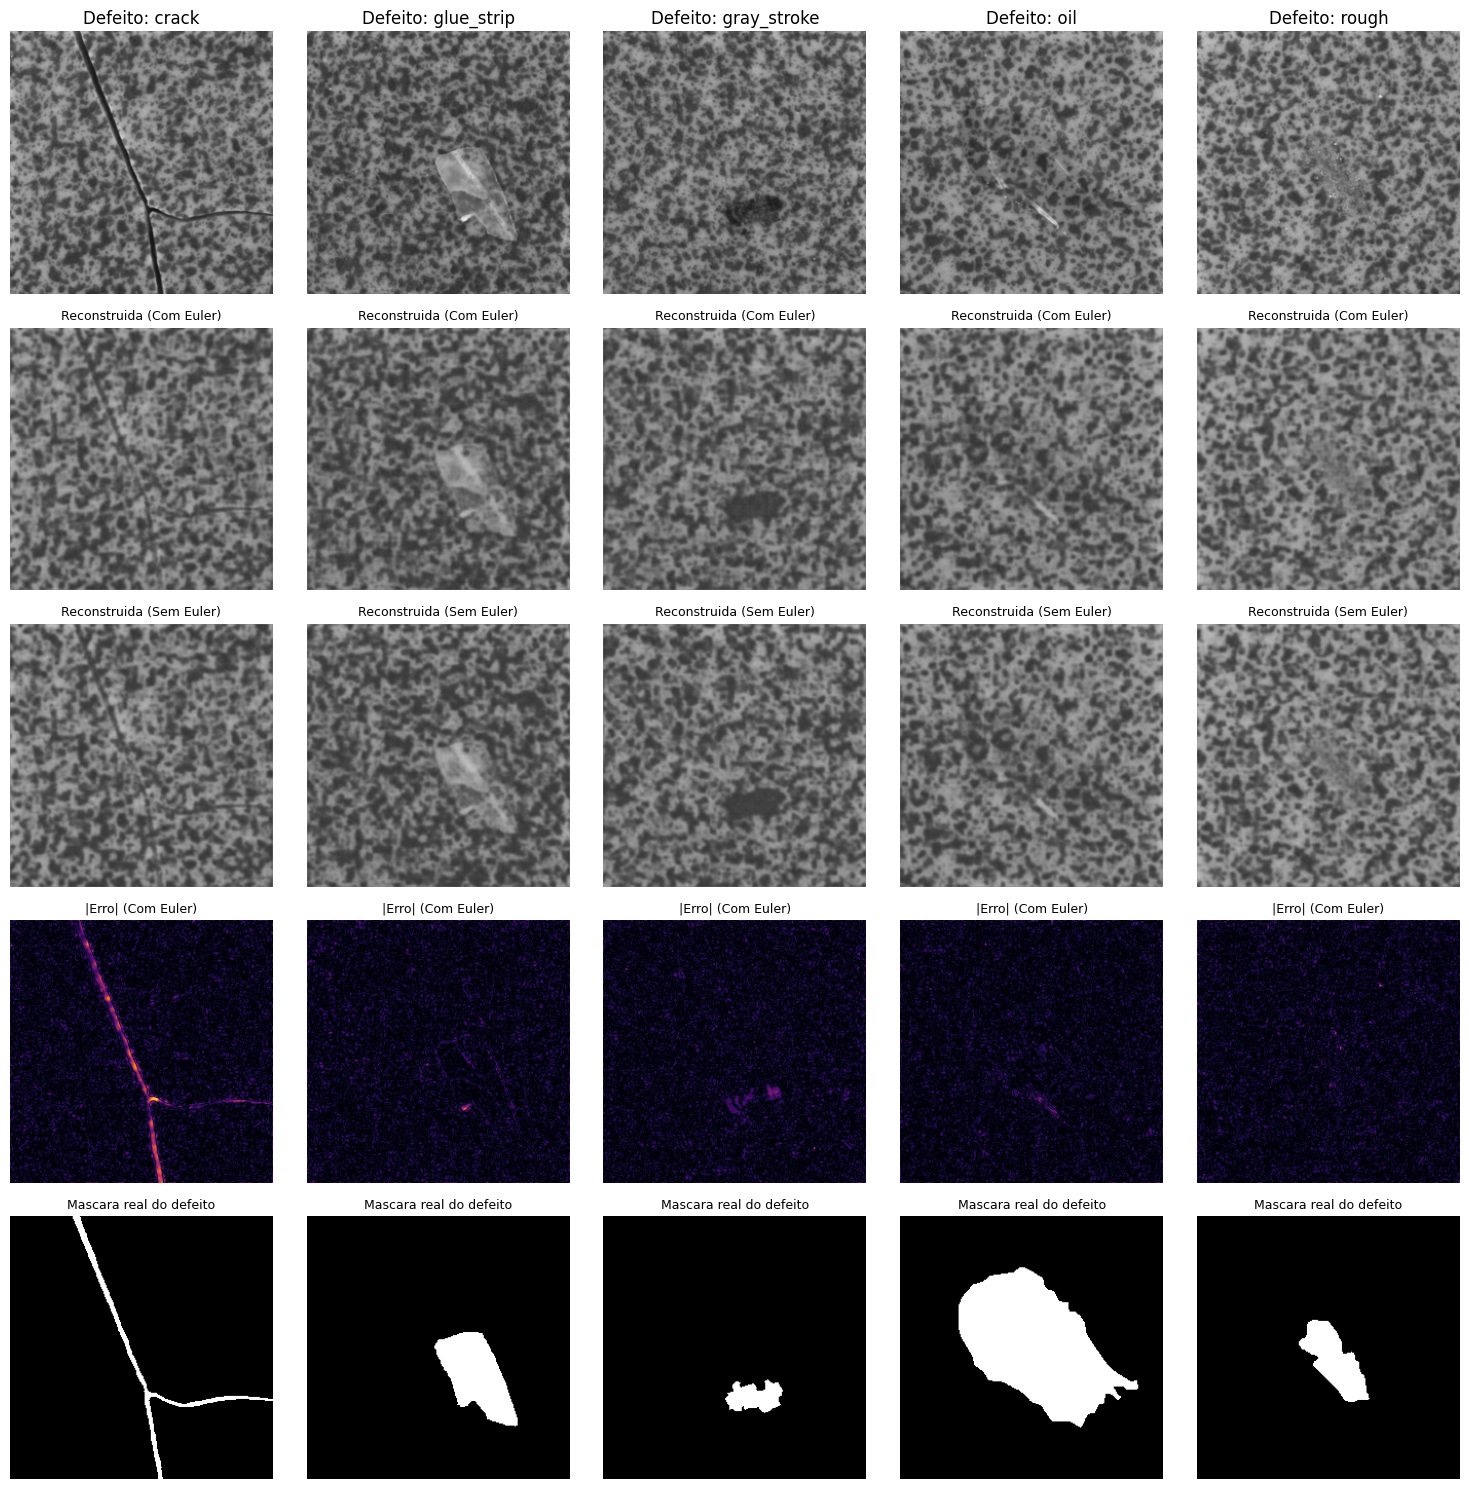

Figuras salvas em: C:\JupyterLab\process_im\resultados


In [9]:
# Imagens de test/<defeito> passam direto pela rede (o defeito real faz o papel do dano). A mascara mostra onde esta o defeito.

PASTA_TESTE = PASTA_TILE / "test"
PASTA_MASCARAS = PASTA_TILE / "ground_truth"

defeitos = sorted(p for p in PASTA_TESTE.iterdir() if p.is_dir() and p.name != "good") if PASTA_TESTE.exists() else []

if not defeitos:
    print("Nenhuma pasta de defeitos encontrada em", PASTA_TESTE)

else:

    nomes_modelos = list(modelos)

    n_linhas = 1 + len(nomes_modelos) + 1 + 1

    fig, eixos = plt.subplots(n_linhas, len(defeitos), figsize=(3 * len(defeitos), 3 * n_linhas), squeeze=False)

    for coluna, pasta in enumerate(defeitos):

        caminho = sorted(pasta.glob("*.png"))[0]
        imagem = carregar_imagem(caminho)
        recs = {n: reconstruir(m, imagem[None])[0] for n, m in modelos.items()}
        caminho_mascara = PASTA_MASCARAS / pasta.name / f"{caminho.stem}_mask.png"

        if caminho_mascara.exists():
            mascara = Image.open(caminho_mascara).convert("L").resize((TAMANHO, TAMANHO), Image.NEAREST)
            mascara = np.asarray(mascara) > 0
        else:
            mascara = np.zeros((TAMANHO, TAMANHO), dtype=bool)

        linha = 0

        eixos[linha, coluna].imshow(imagem[0], cmap="gray", vmin=0, vmax=1)
        eixos[linha, coluna].set_title(f"Defeito: {pasta.name}")

        for nome in nomes_modelos:
            linha += 1
            eixos[linha, coluna].imshow(recs[nome][0], cmap="gray", vmin=0, vmax=1)
            eixos[linha, coluna].set_title(f"Reconstruida ({nome})", fontsize=9)

        linha += 1
        erro = (recs["Com Euler"][0] - imagem[0]).abs()
        eixos[linha, coluna].imshow(erro, cmap="inferno", vmin=0, vmax=0.5)
        eixos[linha, coluna].set_title("|Erro| (Com Euler)", fontsize=9)

        linha += 1
        eixos[linha, coluna].imshow(mascara, cmap="gray")
        eixos[linha, coluna].set_title("Mascara real do defeito", fontsize=9)

        for l in range(n_linhas):
            eixos[l, coluna].axis("off")

    plt.tight_layout()
    plt.savefig(PASTA_SAIDA / "defeitos_reais.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Figuras salvas em:", PASTA_SAIDA.resolve())
